In [1]:
import numpy as np
import pandas as pd
import lseg.data as ld
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller

## Hurst Exponent

Harold Edwin Hurst

    + A british hydrologist who study Nile River

Benoit B. Mandelbrot

    + Borrowed his formula and use it in finance

Hurst Exponent

    + A formula measure long-term memory of time series
        H < 0.5 -> Mean-reverting
        H = 0.5 -> Random Walk
        H > 0.5 -> Trending

In [2]:
ld.open_session()

varA = ld.get_history("EURCAD=", 
                      fields=["BID", "ASK"], 
                      interval="30min", 
                      start="2025-01-01",
                      end="2026-05-16")

print(varA.head())

EURCAD=                 BID     ASK
Timestamp                          
2025-05-16 19:00:00    1.56  1.5606
2025-05-16 19:30:00  1.5586  1.5589
2025-05-16 20:00:00  1.5575  1.5578
2025-05-16 20:30:00  1.5584   1.559
2025-05-18 22:00:00  1.5602   1.561


In [3]:
varA["MID"] = (varA["BID"] + varA["ASK"]) / 2
varA["MID"] = varA["MID"].astype(float)
varA["MID"] = varA["MID"].dropna()

print(varA["MID"].head())

Timestamp
2025-05-16 19:00:00    1.56030
2025-05-16 19:30:00    1.55875
2025-05-16 20:00:00    1.55765
2025-05-16 20:30:00    1.55870
2025-05-18 22:00:00    1.56060
Name: MID, dtype: float64


In [4]:
def adftest(var):
    adf_test = adfuller(var.dropna())
    print()
    print(f"ADF Statistic   : {adf_test[0]:.2f}")
    print(f"p-value         : {adf_test[1]:.2f}")

log_returns = np.log(varA["MID"] / varA["MID"].shift(1))
log_returns = log_returns.dropna()

print(log_returns.head())
adftest(varA["MID"])  

Timestamp
2025-05-16 19:30:00   -0.000994
2025-05-16 20:00:00   -0.000706
2025-05-16 20:30:00    0.000674
2025-05-18 22:00:00    0.001218
2025-05-18 22:30:00    0.000705
Name: MID, dtype: float64

ADF Statistic   : -2.84
p-value         : 0.05


## R/S Analysis

    R = range of cumulative deviation from the mean
    S = standard deviation of the return

In [5]:
chunk = log_returns.iloc[0:100]

mean = chunk.mean()
deviations = chunk - mean
cumulative = deviations.cumsum()

R = cumulative.max() - cumulative.min()
S = chunk.std()
print(f"{R:.4f}")
print(f"{S:.4f}")

RS = R / S
print(f"{RS:.4f}")


0.0087
0.0006
13.6583


In [6]:
n = 100
total_rows = len(log_returns)

rs_values= []

for i in range(total_rows//n):
    chunk = log_returns.iloc[i * n: (i +1) * n]
    mean = chunk.mean()
    deviation = chunk - mean
    cumulative = deviation.cumsum()

    R = cumulative.max() - cumulative.min()
    S = chunk.std()

    RS = R/S

    rs_values.append(RS)

print(f"{np.mean(rs_values):.4f}")

rs_values= []

10.9618


In [7]:
n = [50, 100, 200, 400, 800, 1000, 1400, 2000]

avg_n = []

for i in n:

    rs_values = []

    for j in range(total_rows//i):
        chunk = log_returns.iloc[j * i: (j + 1) * i]
        mean = chunk.mean()
        deviation = chunk - mean
        cumulative = deviation.cumsum()

        R = cumulative.max() - cumulative.min()
        S = chunk.std()

        RS = R/S

        rs_values.append(RS)
    
    avg_rs = np.mean(rs_values)
    avg_n.append((i, avg_rs))


In [8]:
for n, rs in avg_n:
    print(f"n: {n:5d}  avg R/S: {rs:.4f}")

n:    50  avg R/S: 7.6227
n:   100  avg R/S: 10.9618
n:   200  avg R/S: 15.4008
n:   400  avg R/S: 22.0264
n:   800  avg R/S: 29.8565
n:  1000  avg R/S: 35.5542
n:  1400  avg R/S: 38.3265
n:  2000  avg R/S: 49.1900


In [9]:
ns = [x[0] for x in avg_n]
rs = [x[1] for x in avg_n]

log_ns = np.log(ns)
log_rs = np.log(rs)

H = np.polyfit(log_ns, log_rs, 1)[0]
print(f"Hurst Exponent: {H:.4f}")

Hurst Exponent: 0.4968


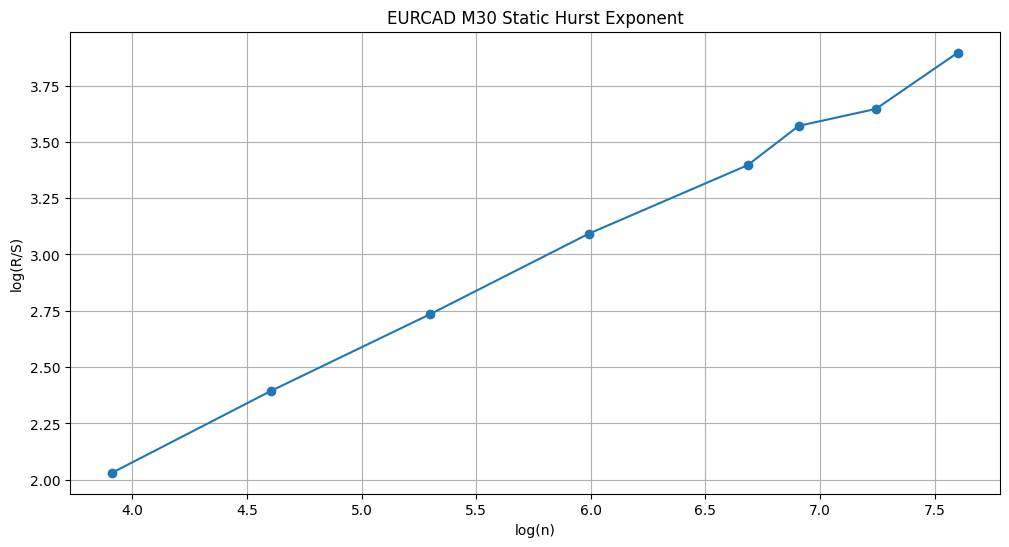

In [10]:
plt.figure(figsize=(12,6))
plt.plot(log_ns, log_rs, "o-")
plt.xlabel("log(n)")
plt.ylabel("log(R/S)")
plt.title("EURCAD M30 Static Hurst Exponent")
plt.grid(True)
plt.show()